# Assumptions
As we saw with the normal linear model, once the model has been estimated we need to assess whether the assumptions are met before proceeding to inference. Under the normal linear model, we only had a single set of assumptions. Under a GLM, we have a set of assumptions that are generic across GLMs, but we also need to consider these within the context of the specific GLM we are using. As such, not every diagnostic is going to be informative or even relevant for every GLM. Binary logistic regression is a good example of this, because the assumptions turn out to be very minimal.


## Binary Logistic Regression Assumptions
Under the binary logistic GLM we have been using, the conditional distribution of the outcome variable is

$$
    (y_{i} | x_{i1}, x_{i2}, \dots, x_{ik}) \sim \text{Bern}(\pi_{i}).
$$

In words, the distribution of $y_{i}$, conditional on the values of all the predictor variables, is assumed to be Bernoulli with a specific probability of success $\pi_{i}$. Thus the three aspects of the GLM become

$$
\begin{align*}
    E(y_{i})   &= \pi_{i} \\
    \log\left(\frac{\pi_{i}}{1 - \pi_{i}}\right) &= \beta_{0} + \beta_{1}x_{i1} + \dots + \beta_{k}x_{ik} \\
    \text{Var}(y_{i}) &= \pi_{i}(1 - \pi_{i})
\end{align*}
$$

This then leads to the following interpretations of the assumptions:

1. The observations are independent of each other (no correlation).
    - This remains the case for all GLMs, but is a function of the *design* rather than something we check. If each observation comes from a different subject with no repeated measurements, we can assume independence.
2. The observations follow the assumed conditional distribution of the outcome variable.
    - This remains the case, however, for binary data the Bernoulli distribution is *always* true and so does not need establishing or checking.
3. The transformed mean is accurately described using the assumed regression model.
    - This is a key assumption that will need to be checked. On the scale of the link function, we assume the relationship can still be captured by a straight-line and may need to use non-linear methods if this is not the case.
4. The conditional variance follows the form for the assumed distribution.
    - This remain true, but is trivial for the Bernoulli distribution because the variance depends entirely on the value of $\pi_{i}$. As such, if the mean is correctly specified then the variance will automatically be correct as well. 

From this we can conclude that the only real element we need to check is the accuracy of the regression model on the scale of the link function. This does include multiple aspects, such as checking whether a straight line is an accurate model and checking for outliers. However, this is fairly trivial in terms of the number of assumptions that need to be met. This is not always true of other GLMs, but is true of binary logistic regression.

## Residual Plots
... To facilitate this, we can create plots of the model fit 

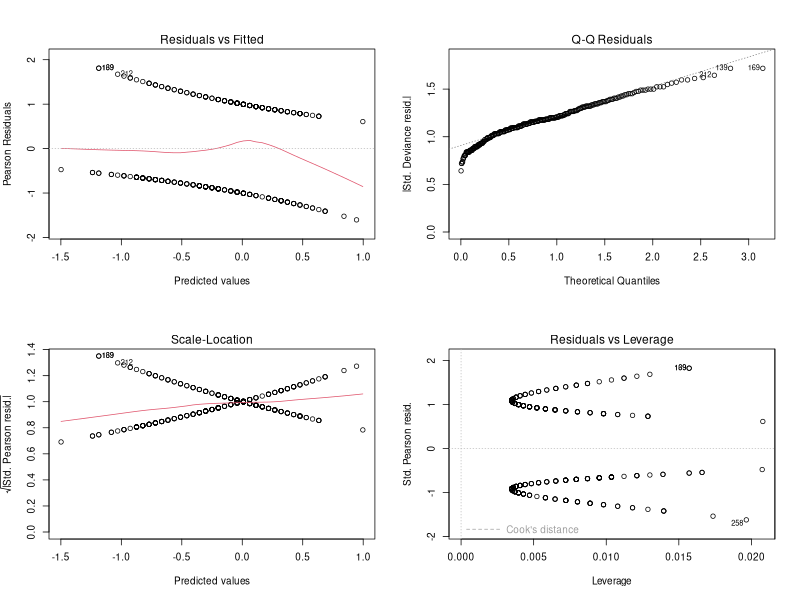

In [15]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

## Plots of the Model Fit

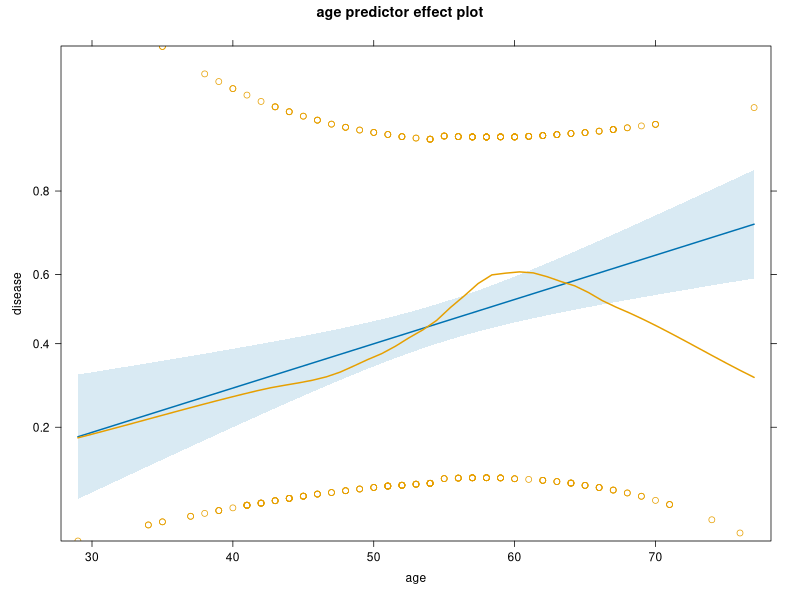

In [10]:
library('datarium')
library('effects')

data('heartdisease')

cleveland         <- subset(heartdisease, dataset == "cleveland")
cleveland$disease <- as.integer(cleveland$num > 0)
cleveland$sex     <- as.factor(cleveland$sex)

mod <- glm(disease ~ age, family=binomial(link=logit), data=cleveland)

plot(predictorEffects(mod, partial.residuals = TRUE))

The model fit is therefore supposed to represent the conditional average of the points across the two values of the outcome. This will depend upon the number of individual points with values of either 1 or 0 at each value of age, which we cannot see visually because they overlap. However, we can see this using the LOESS smoothing line. Notice the lump around age 60. This suggests that there is a sudden increase in the number of subjects with the disease at that age, more than predicted by the regression line. Notice that this then drops sharply, suggesting a sudden decrease in the number of subjects with the disease. This is not predicted by the regression line. This may suggest that there is a non-linear effect of age, which might push us towards the incorporation of polynomial terms.

We also need to think carefully about the context here. If the disease in question comes with increased risk of mortality at an older age, we might be seeing a form of *survivorship bias*, where the probability is skewed by the fact that there are fewer individuals with the disease simply because they have died. So, the probability of having the disease *does* decrease, but this is because after a certain age those with the disease are most likely to have died.